# 04 · Strategy simulator

**Goal:** for each team at the next race, find the fastest pit strategy (one-stop or two-stop, which tires, when to stop) and how sure we can be about it.

Ingredients, all measured from our own data:
- **Tire wear by team** (notebook 03), with its uncertainty
- **Fuel effect and compound offsets** (field model, this season)
- **Pit stop time loss at this circuit:** pit-in lap + pit-out lap, vs. two normal laps
- **How hard this circuit is on tires,** from past races here
- **Realistic stint lengths:** our wear model is a straight line and can't see a tire "falling off a cliff", so stints are capped at lengths teams actually run

In [1]:
from pathlib import Path

import pandas as pd
import plotly.express as px

from degradation import fit_degradation
from strategy import (best_plans, circuit_profile, max_stint_laps, pit_loss_by_event,
                      simulate, upcoming_races)

DATA = Path("..") / "app" / "data"
SKIP = 5     # opening laps dropped (notebook 02)
K = 0.9      # team_wear.parquet stores seconds on a 90 s lap; divide by K to get % per lap

raw = pd.read_parquet(DATA / "laps.parquet")
clean = pd.read_parquet(DATA / "clean_laps.parquet")
team_wear = pd.read_parquet(DATA / "team_wear.parquet")
SEASON = int(clean["SEASON"].max())

## 1. Shared ingredients

The field model for this season gives the fuel effect, the hard tire's offset (how much slower a fresh hard is than a fresh medium), and the average wear that each circuit is compared against.

**Soft tires need a decision.** Notebook 02 found that 2026 softs look implausible: a new soft no faster than a new medium, and wearing *less*. Fed into the simulator, that makes softs the best tire on every measure, so every team gets the longest soft stint the caps allow. By default, softs therefore use their **pre-2026** speed and wear. Set `SOFT_SOURCE = "2026"` to see what the 2026 numbers recommend instead. Section 3 compares the two.

In [2]:
SOFT_SOURCE = "before 2026"   # or "2026"

field = fit_degradation(clean[clean["SEASON"] == SEASON], skip_opening_laps=SKIP)
field_before = fit_degradation(clean[clean["SEASON"] < SEASON], skip_opening_laps=SKIP)
all_wear = fit_degradation(clean, skip_opening_laps=SKIP)
soft_from = {"2026": field, "before 2026": field_before}
caps = max_stint_laps(raw, SEASON)
pit_losses = pit_loss_by_event(raw)

pd.Series({
    "fuel (% per lap)": field["fuel"],
    "fresh HARD vs MEDIUM (%)": field["offset_HARD"],
    "fresh SOFT vs MEDIUM (%), 2026": field["offset_SOFT"],
    "fresh SOFT vs MEDIUM (%), before 2026": field_before["offset_SOFT"],
    "SOFT wear (% per lap), 2026": field["deg_SOFT"],
    "SOFT wear (% per lap), before 2026": field_before["deg_SOFT"],
    **{f"max stint {c} (laps)": caps.get(c) for c in ["SOFT", "MEDIUM", "HARD"]},
}).round(3)

fuel (% per lap)                         -0.045
fresh HARD vs MEDIUM (%)                 -0.062
fresh SOFT vs MEDIUM (%), 2026            0.093
fresh SOFT vs MEDIUM (%), before 2026    -0.442
SOFT wear (% per lap), 2026               0.019
SOFT wear (% per lap), before 2026        0.072
max stint SOFT (laps)                    32.000
max stint MEDIUM (laps)                  41.000
max stint HARD (laps)                    47.000
dtype: float64

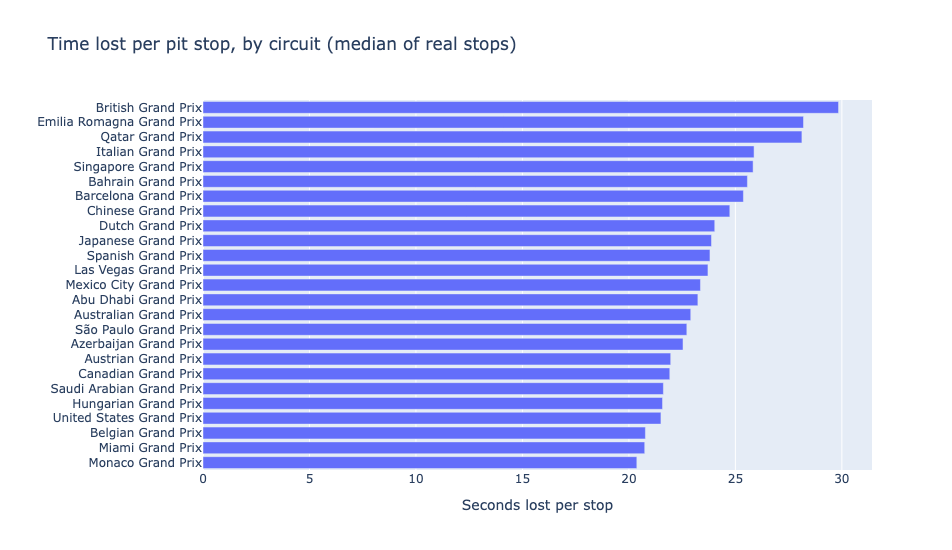

In [3]:
fig = px.bar(pit_losses.sort_values().rename("seconds").reset_index(),
             x="seconds", y="EVENT_NAME", orientation="h",
             title="Time lost per pit stop, by circuit (median of real stops)",
             labels={"EVENT_NAME": "", "seconds": "Seconds lost per stop"})
fig.update_layout(height=max(400, 22 * len(pit_losses)))
fig.show()

## 2. The next race

Pulls the remaining races from OpenF1. If that fails (no internet), set `EVENT` by hand to any event name in the data.

In [4]:
try:
    upcoming = upcoming_races(SEASON)
    display(upcoming)
    EVENT = upcoming["meeting_name"].iloc[0]
except Exception as exc:
    print(f"Couldn't load the schedule ({exc}); using the most recent event instead.")
    EVENT = clean.loc[clean["SEASON"] == SEASON].sort_values("RACE_ROUND")["EVENT_NAME"].iloc[-1]

circuit = circuit_profile(EVENT, raw, clean, pit_losses, all_wear, skip=SKIP)
pd.Series(circuit)

,meeting_name,circuit_short_name,date_start
0,United States Grand Prix,Austin,2026-10-25 20:00:00+00:00
1,Mexico City Grand Prix,Mexico City,2026-11-01 20:00:00+00:00
2,São Paulo Grand Prix,Interlagos,2026-11-08 17:00:00+00:00
3,Las Vegas Grand Prix,Las Vegas,2026-11-22 04:00:00+00:00
4,Qatar Grand Prix,Lusail,2026-11-29 16:00:00+00:00
5,Abu Dhabi Grand Prix,Yas Marina Circuit,2026-12-06 13:00:00+00:00


event                United States Grand Prix
laps                                       56
base_lap                              100.293
past_races                                  3
pit_loss                               21.504
pit_loss_measured                        True
wear_factor_raw                      1.315193
wear_factor                          1.189116
dtype: object

**How to read this:** `wear_factor` above 1 means this circuit is harder on tires than average (1.3 = 30% more wear). It's pulled toward 1.0 when there are few past races here. If `past_races` is 0 (a new circuit, or a renamed event), the circuit is treated as average and the pit loss falls back to 22 s.

## 3. Best strategy for every team

In [5]:
def team_params(team: str, which: str = "pooled", soft_source: str = SOFT_SOURCE) -> dict:
    """Lap-model inputs for one team. `which` = pooled, low, or high wear."""
    soft = soft_from[soft_source]
    p = {"fuel": field["fuel"], "offset_SOFT": soft["offset_SOFT"],
         "offset_HARD": field["offset_HARD"],
         "wear_SOFT": max(soft["deg_SOFT"], 0.0) * circuit["wear_factor"]}
    for c in ["MEDIUM", "HARD"]:
        row = team_wear[(team_wear["team"] == team) & (team_wear["compound"] == c)]
        wear = row[which].iloc[0] / K if len(row) else field[f"deg_{c}"]
        p[f"wear_{c}"] = wear * circuit["wear_factor"]
    return p


def run(team: str, which: str = "pooled", soft_source: str = SOFT_SOURCE) -> pd.DataFrame:
    sims = simulate(team_params(team, which, soft_source), circuit["laps"],
                    circuit["base_lap"], circuit["pit_loss"], caps.to_dict())
    return best_plans(sims)


rows = []
for team in sorted(team_wear["team"].unique()):
    plans = run(team)
    best, runner_up = plans.iloc[0], plans.iloc[1]
    # Robustness: does the best plan change if the team's wear is at the low or high end?
    alt = {w: run(team, w).iloc[0]["plan"] for w in ["low", "high"]}
    rows.append({
        "team": team,
        "best plan": best["plan"],
        "order": best["best order"],
        "pit lap(s)": ", ".join(map(str, best["pit_laps"])),
        "pit window": best["window"],
        "next best": runner_up["plan"],
        "margin (s)": round(runner_up["vs_best"], 1),
        "robust": "yes" if set(alt.values()) == {best["plan"]} else
                  f"no: low wear → {alt['low']}, high wear → {alt['high']}",
    })
recommendations = pd.DataFrame(rows)
recommendations

,team,best plan,order,pit lap(s),pit window,next best,margin (s),robust
0,Alpine,HARD + MEDIUM,MEDIUM → HARD,27,laps 22–32,HARD + SOFT,3.6,yes
1,Aston Martin,HARD + MEDIUM,MEDIUM → HARD,27,laps 22–32,HARD + SOFT,2.9,yes
2,Audi,HARD + MEDIUM,MEDIUM → HARD,27,laps 22–32,HARD + SOFT,2.8,yes
3,Cadillac,HARD + MEDIUM,MEDIUM → HARD,26,laps 22–30,HARD + SOFT,1.7,"no: low wear → HARD + MEDIUM, high wear → HARD..."
4,Ferrari,HARD + MEDIUM,MEDIUM → HARD,27,laps 22–31,HARD + SOFT,2.7,yes
5,Haas F1 Team,HARD + MEDIUM,MEDIUM → HARD,27,laps 23–31,HARD + SOFT,2.2,"no: low wear → HARD + MEDIUM, high wear → HARD..."
6,McLaren,HARD + MEDIUM,MEDIUM → HARD,26,laps 21–31,HARD + SOFT,1.9,"no: low wear → HARD + MEDIUM, high wear → HARD..."
7,Mercedes,HARD + MEDIUM,MEDIUM → HARD,28,laps 23–32,HARD + SOFT,4.0,yes
8,Racing Bulls,HARD + MEDIUM,MEDIUM → HARD,24,laps 20–29,HARD + SOFT,0.5,"no: low wear → HARD + MEDIUM, high wear → HARD..."
9,Red Bull Racing,HARD + MEDIUM,MEDIUM → HARD,26,laps 21–30,HARD + SOFT,1.6,"no: low wear → HARD + MEDIUM, high wear → HARD..."


### Does the soft-tire assumption change the answer?

The same simulation for every team, once with each set of soft numbers. If the plans differ, the recommendation hinges on how 2026 softs really behave, and that's the honest headline.

In [6]:
rows = []
for team in sorted(team_wear["team"].unique()):
    row = {"team": team}
    for source in ["before 2026", "2026"]:
        best = run(team, soft_source=source).iloc[0]
        row[f"plan ({source} softs)"] = best["plan"]
        row[f"stop lap(s) ({source} softs)"] = ", ".join(map(str, best["pit_laps"]))
    rows.append(row)
compare = pd.DataFrame(rows)
compare["same plan?"] = compare["plan (before 2026 softs)"] == compare["plan (2026 softs)"]
compare

,team,plan (before 2026 softs),stop lap(s) (before 2026 softs),plan (2026 softs),stop lap(s) (2026 softs),same plan?
0,Alpine,HARD + MEDIUM,27,HARD + SOFT,32,False
1,Aston Martin,HARD + MEDIUM,27,HARD + SOFT,32,False
2,Audi,HARD + MEDIUM,27,HARD + SOFT,32,False
3,Cadillac,HARD + MEDIUM,26,HARD + SOFT,32,False
4,Ferrari,HARD + MEDIUM,27,HARD + SOFT,32,False
5,Haas F1 Team,HARD + MEDIUM,27,HARD + SOFT,32,False
6,McLaren,HARD + MEDIUM,26,HARD + SOFT,32,False
7,Mercedes,HARD + MEDIUM,28,HARD + SOFT,32,False
8,Racing Bulls,HARD + MEDIUM,24,HARD + SOFT,32,False
9,Red Bull Racing,HARD + MEDIUM,26,HARD + SOFT,24,False


**How to read this:**
- **pit window:** every pit lap within 1 s of the best one. A wide window means stopping a few laps early or late barely matters. A one-lap window (like "laps 26–26") usually means the stint-length caps forced that lap, not tire wear: the plan only fits the race distance with a stop right there.
- **margin:** how much slower the next-best plan is. Under ~3 s, the plans are effectively tied: traffic or a safety car will matter more.
- **robust:** whether the best plan stays the same across the team's whole uncertainty range for tire wear.
- **order:** in this model the order of stints doesn't change the total, so "SOFT → HARD, stop lap 32" and "HARD → SOFT, stop lap 24" (on a 56-lap race) are the same plan, mirrored. Real teams choose the order for other reasons, like track position at the start.

## 4. One team in detail

How total race time changes with the pit lap, for each one-stop plan. The flat bottom of each curve is the pit window. The dashed line is the best two-stop.

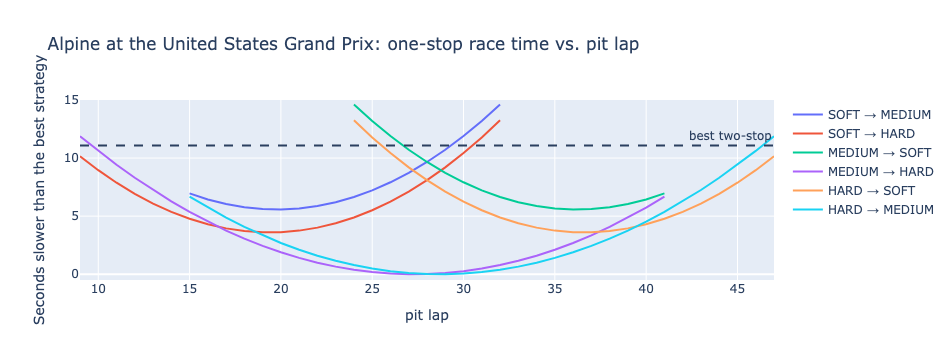

In [7]:
TEAM = recommendations["team"].iloc[0]     # change to any team name

sims = simulate(team_params(TEAM), circuit["laps"], circuit["base_lap"],
                circuit["pit_loss"], caps.to_dict())
one = sims[sims["stops"] == 1].copy()
one["pit lap"] = one["pit_laps"].str[0]
best_two = sims.loc[sims["stops"] == 2, "vs_best"].min()

fig = px.line(one, x="pit lap", y="vs_best", color="plan",
              title=f"{TEAM} at the {EVENT}: one-stop race time vs. pit lap",
              labels={"vs_best": "Seconds slower than the best strategy", "plan": ""})
if pd.notna(best_two):
    fig.add_hline(y=best_two, line_dash="dash", annotation_text="best two-stop")
fig.update_yaxes(range=[-0.5, 15])
fig.show()

## 5. Save for the dashboard

In [8]:
out = recommendations.assign(event=EVENT, season=SEASON, soft_source=SOFT_SOURCE,
                             laps=circuit["laps"], pit_loss=circuit["pit_loss"],
                             wear_factor=circuit["wear_factor"])
out.to_parquet(DATA / "strategy_next_race.parquet", index=False)
out.head(3)

,team,best plan,order,pit lap(s),pit window,next best,margin (s),robust,event,season,soft_source,laps,pit_loss,wear_factor
0,Alpine,HARD + MEDIUM,MEDIUM → HARD,27,laps 22–32,HARD + SOFT,3.6,yes,United States Grand Prix,2026,before 2026,56,21.504,1.189116
1,Aston Martin,HARD + MEDIUM,MEDIUM → HARD,27,laps 22–32,HARD + SOFT,2.9,yes,United States Grand Prix,2026,before 2026,56,21.504,1.189116
2,Audi,HARD + MEDIUM,MEDIUM → HARD,27,laps 22–32,HARD + SOFT,2.8,yes,United States Grand Prix,2026,before 2026,56,21.504,1.189116


## What this model leaves out

These are worth saying out loud in an interview, because they're the reasons real strategists still earn their pay:
- **Safety cars.** A safety car makes a pit stop much cheaper, and it often decides a race's strategy. Adding historical safety-car odds per circuit is a natural next step.
- **Track position and traffic.** The model treats each car as alone on track. In reality, undercuts, overcuts, and getting stuck behind slower cars change the picture (your historical undercut findings are relevant here).
- **Tire cliffs.** Wear is a straight line, capped at realistic stint lengths. Real tires can fall away suddenly.
- **Weather and track temperature.** Not in the data yet.
- **Starting tires.** Every stint is assumed to start on a fresh set.